In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../datos/procesados/base_completa.csv")

print(df.shape)
print(df["TARGET"].value_counts())
print(df["TARGET"].mean())

(307511, 145)
TARGET
0    282686
1     24825
Name: count, dtype: int64
0.08072881945686496


In [2]:
def tasa_por_grupo(df, columna, min_clientes=1000):
    """Tasa de incumplimiento por categoría de una columna.
    Descarta grupos con menos de min_clientes (tasas inestables)."""
    tabla = (
        df.groupby(columna, observed=True)["TARGET"]
        .agg(clientes="count", incumplen="sum", tasa="mean")
        .reset_index()
    )
    tabla["tasa"] = (tabla["tasa"] * 100).round(2)
    tabla = tabla[tabla["clientes"] >= min_clientes]
    return tabla.sort_values("tasa", ascending=False)

tasa_por_grupo(df, "RANGO_EDAD")

,RANGO_EDAD,clientes,incumplen,tasa
0,20-29,45000,5155,11.46
1,30-39,82299,7885,9.58
2,40-49,76543,5860,7.66
3,50-59,68074,4173,6.13
4,60-69,35595,1752,4.92


In [3]:
for col in ["NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE"]:
    print(f"\n--- {col} ---")
    print(tasa_por_grupo(df, col).to_string(index=False))


--- NAME_CONTRACT_TYPE ---
NAME_CONTRACT_TYPE  clientes  incumplen  tasa
        Cash loans    278232      23221  8.35
   Revolving loans     29279       1604  5.48

--- CODE_GENDER ---
CODE_GENDER  clientes  incumplen  tasa
          M    105059      10655 10.14
          F    202448      14170  7.00

--- NAME_EDUCATION_TYPE ---
          NAME_EDUCATION_TYPE  clientes  incumplen  tasa
              Lower secondary      3816        417 10.93
Secondary / secondary special    218391      19524  8.94
            Incomplete higher     10277        872  8.48
             Higher education     74863       4009  5.36

--- NAME_INCOME_TYPE ---
    NAME_INCOME_TYPE  clientes  incumplen  tasa
             Working    158774      15224  9.59
Commercial associate     71617       5360  7.48
       State servant     21703       1249  5.75
           Pensioner     55362       2982  5.39


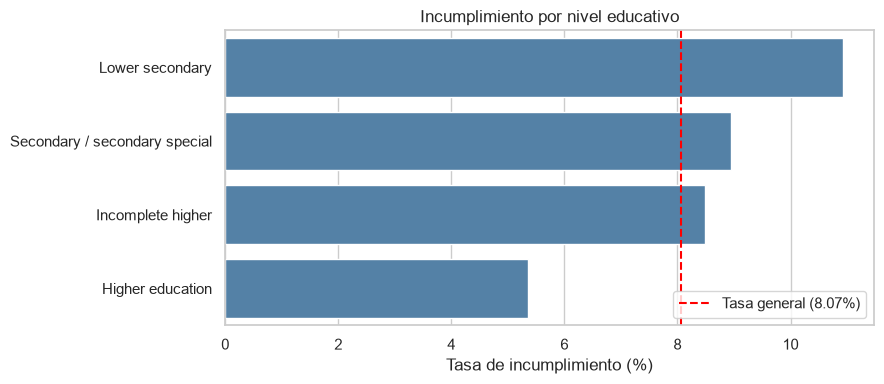

In [4]:
tabla_edu = tasa_por_grupo(df, "NAME_EDUCATION_TYPE")

plt.figure(figsize=(9, 4))
sns.barplot(data=tabla_edu, x="tasa", y="NAME_EDUCATION_TYPE", color="steelblue")
plt.axvline(8.07, color="red", linestyle="--", label="Tasa general (8.07%)")
plt.xlabel("Tasa de incumplimiento (%)")
plt.ylabel("")
plt.title("Incumplimiento por nivel educativo")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [5]:
def tasa_cruzada(df, fila, min_clientes=1000):
    """Tasa de incumplimiento (%) de hombres y mujeres dentro de cada categoría de 'fila'."""
    tasas = df.pivot_table(index=fila, columns="CODE_GENDER", values="TARGET",
                           aggfunc="mean", observed=True) * 100
    conteo = df.pivot_table(index=fila, columns="CODE_GENDER", values="TARGET",
                            aggfunc="count", observed=True)
    tasas = tasas[(conteo >= min_clientes).all(axis=1)]
    tasas["diferencia_M_menos_F"] = tasas["M"] - tasas["F"]
    return tasas.round(2)

for col in ["NAME_CONTRACT_TYPE", "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE", "RANGO_EDAD"]:
    print(f"\n--- {col} ---")
    print(tasa_cruzada(df, col))


--- NAME_CONTRACT_TYPE ---
CODE_GENDER            F      M  diferencia_M_menos_F
NAME_CONTRACT_TYPE                                   
Cash loans          7.18  10.58                  3.40
Revolving loans     5.31   5.83                  0.52

--- NAME_EDUCATION_TYPE ---
CODE_GENDER                       F      M  diferencia_M_menos_F
NAME_EDUCATION_TYPE                                             
Higher education               4.85   6.39                  1.55
Incomplete higher              8.02   9.22                  1.19
Lower secondary                9.26  13.49                  4.23
Secondary / secondary special  7.68  11.36                  3.69

--- NAME_INCOME_TYPE ---
CODE_GENDER              F      M  diferencia_M_menos_F
NAME_INCOME_TYPE                                       
Commercial associate  6.67   8.83                  2.16
Pensioner             4.96   7.32                  2.36
State servant         5.34   6.88                  1.53
Working               8.37  11.

In [6]:
print(tasa_cruzada(df, "RANGO_EDAD").to_string())
print(pd.crosstab(df["NAME_CONTRACT_TYPE"], df["CODE_GENDER"]))

CODE_GENDER      F      M  diferencia_M_menos_F
RANGO_EDAD                                     
20-29        10.62  12.55                  1.92
30-39         8.70  10.95                  2.24
40-49         6.69   9.44                  2.75
50-59         5.11   8.82                  3.72
60-69         4.52   6.38                  1.86
CODE_GENDER              F      M
NAME_CONTRACT_TYPE               
Cash loans          182800  95432
Revolving loans      19648   9627


In [7]:
df["GRUPO_INGRESO"] = np.where(df["NAME_INCOME_TYPE"] == "Pensioner", "Pensionado", "No pensionado")

tasas = df.pivot_table(index="RANGO_EDAD", columns="GRUPO_INGRESO",
                       values="TARGET", aggfunc="mean", observed=True) * 100
conteo = df.pivot_table(index="RANGO_EDAD", columns="GRUPO_INGRESO",
                        values="TARGET", aggfunc="count", observed=True)

print(tasas.round(2))
print(conteo)

GRUPO_INGRESO  No pensionado  Pensionado
RANGO_EDAD                              
20-29                  11.45       13.64
30-39                   9.57       11.45
40-49                   7.63        8.54
50-59                   6.49        5.43
60-69                   4.46        5.02
GRUPO_INGRESO  No pensionado  Pensionado
RANGO_EDAD                              
20-29                  44868         132
30-39                  81801         498
40-49                  74728        1815
50-59                  44742       23332
60-69                   6010       29585


C:\Users\javie\AppData\Local\Temp\ipykernel_27448\428539599.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["GRUPO_INGRESO"] = np.where(df["NAME_INCOME_TYPE"] == "Pensioner", "Pensionado", "No pensionado")


In [8]:
df = df.copy()

df["TRAMO_ANTIGUEDAD"] = pd.cut(
    df["ANTIGUEDAD_LABORAL_ANIOS"],
    bins=[0, 1, 2, 5, 10, 20, 60],
    include_lowest=True
)

tasas = df.pivot_table(index="TRAMO_ANTIGUEDAD", columns="RANGO_EDAD",
                       values="TARGET", aggfunc="mean", observed=True) * 100
conteo = df.pivot_table(index="TRAMO_ANTIGUEDAD", columns="RANGO_EDAD",
                        values="TARGET", aggfunc="count", observed=True)

print(tasas.round(2))
print(conteo)

RANGO_EDAD        20-29  30-39  40-49  50-59  60-69
TRAMO_ANTIGUEDAD                                   
(-0.001, 1.0]     12.18  11.72  10.05   8.60   4.93
(1.0, 2.0]        12.69  12.40  10.40   8.65   5.25
(2.0, 5.0]        11.48  10.98   8.86   8.16   6.00
(5.0, 10.0]        9.52   7.72   6.99   6.14   4.18
(10.0, 20.0]       7.80   6.31   5.32   4.86   4.12
(20.0, 60.0]        NaN   5.56   4.64   3.97   2.73
RANGO_EDAD          20-29    30-39    40-49    50-59   60-69
TRAMO_ANTIGUEDAD                                            
(-0.001, 1.0]      8126.0   9126.0   6922.0   3443.0   365.0
(1.0, 2.0]         8981.0  10471.0   7867.0   4069.0   457.0
(2.0, 5.0]        18839.0  25802.0  19917.0  10659.0  1267.0
(5.0, 10.0]        8546.0  23408.0  19966.0  11470.0  1482.0
(10.0, 20.0]        372.0  12684.0  14637.0   9369.0  1336.0
(20.0, 60.0]          NaN    306.0   5412.0   5738.0  1100.0


In [9]:
resumen = {}
for col in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
    decil = pd.qcut(df[col], 10, labels=False, duplicates="drop") + 1
    resumen[col] = df.groupby(decil)["TARGET"].mean() * 100

tabla_deciles = pd.DataFrame(resumen).round(2)
tabla_deciles.index.name = "decil (1 = score más bajo)"
print(tabla_deciles)

                            EXT_SOURCE_1  EXT_SOURCE_2  EXT_SOURCE_3
decil (1 = score más bajo)                                          
1.0                                17.56         18.35         20.00
2.0                                11.59         12.08         12.75
3.0                                 9.09          9.96          9.51
4.0                                 8.38          8.36          7.98
5.0                                 6.69          7.42          6.18
6.0                                 6.02          6.65          5.34
7.0                                 5.14          5.85          4.74
8.0                                 4.38          4.88          4.21
9.0                                 3.51          4.20          3.53
10.0                                2.57          2.97          3.23


In [10]:
for col in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
    t = df.groupby(df[col].isna())["TARGET"].agg(clientes="count", tasa="mean")
    t["tasa"] = (t["tasa"] * 100).round(2)
    t.index = ["con dato", "sin dato (NaN)"]
    print(f"\n--- {col} ---")
    print(t)


--- EXT_SOURCE_1 ---
                clientes  tasa
con dato          134133  7.50
sin dato (NaN)    173378  8.52

--- EXT_SOURCE_2 ---
                clientes  tasa
con dato          306851  8.07
sin dato (NaN)       660  7.88

--- EXT_SOURCE_3 ---
                clientes  tasa
con dato          246546  7.77
sin dato (NaN)     60965  9.31


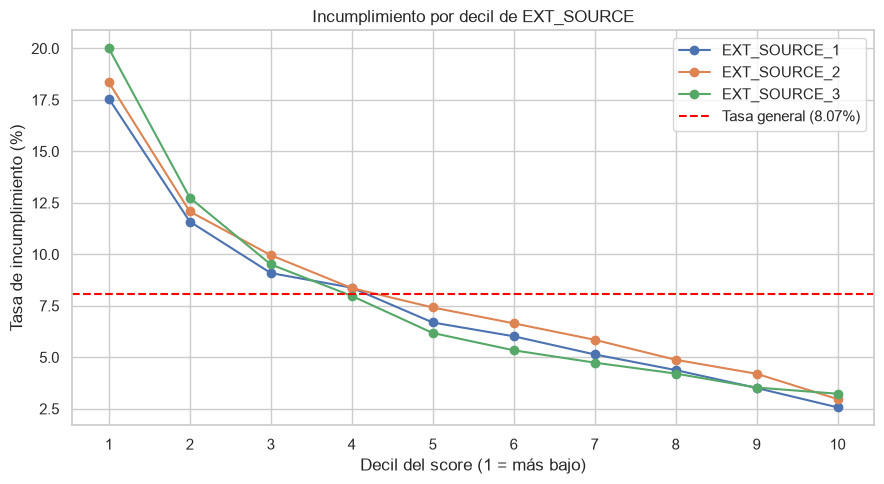

              EXT_SOURCE_1  EXT_SOURCE_2  EXT_SOURCE_3  TARGET
EXT_SOURCE_1         1.000         0.214         0.187  -0.155
EXT_SOURCE_2         0.214         1.000         0.109  -0.160
EXT_SOURCE_3         0.187         0.109         1.000  -0.179
TARGET              -0.155        -0.160        -0.179   1.000


In [11]:
tabla_deciles.plot(marker="o", figsize=(9, 5))
plt.axhline(8.07, color="red", linestyle="--", label="Tasa general (8.07%)")
plt.xlabel("Decil del score (1 = más bajo)")
plt.ylabel("Tasa de incumplimiento (%)")
plt.title("Incumplimiento por decil de EXT_SOURCE")
plt.xticks(range(1, 11))
plt.legend()
plt.tight_layout()
plt.savefig("../imagenes/ext_source_deciles.png", dpi=150)
plt.show()

print(df[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "TARGET"]].corr().round(3))

In [12]:
cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]

completos = df.loc[df[cols].notna().all(axis=1), cols + ["TARGET"]].copy()
completos["EXT_PROMEDIO"] = completos[cols].mean(axis=1)

print("Clientes con las tres fuentes:", len(completos))
print("Tasa de este grupo:", round(completos["TARGET"].mean() * 100, 2))

resumen2 = {}
for col in cols + ["EXT_PROMEDIO"]:
    decil = pd.qcut(completos[col], 10, labels=False, duplicates="drop") + 1
    resumen2[col] = completos.groupby(decil)["TARGET"].mean() * 100

print(pd.DataFrame(resumen2).round(2))

Clientes con las tres fuentes: 109589
Tasa de este grupo: 7.3
    EXT_SOURCE_1  EXT_SOURCE_2  EXT_SOURCE_3  EXT_PROMEDIO
1          17.00         16.06         19.10         23.37
2          11.32         10.57         12.11         13.10
3           8.96          9.23          8.59          9.14
4           8.17          7.50          7.34          7.29
5           6.44          6.57          5.97          5.86
6           5.96          6.24          4.99          4.65
7           5.03          5.51          4.37          3.37
8           4.19          4.68          4.17          2.78
9           3.53          3.59          3.23          2.14
10          2.38          3.04          2.98          1.28


In [13]:
for col in ["RATIO_CUOTA_INGRESO", "PLAZO_ANIOS"]:
    decil = pd.qcut(df[col], 10, labels=False, duplicates="drop") + 1
    t = df.groupby(decil).agg(
        clientes=("TARGET", "count"),
        desde=(col, "min"),
        hasta=(col, "max"),
        tasa=("TARGET", "mean"),
    )
    t["tasa"] = (t["tasa"] * 100).round(2)
    print(f"\n--- {col} ---")
    print(t.round(2).to_string())


--- RATIO_CUOTA_INGRESO ---
                     clientes  desde  hasta  tasa
RATIO_CUOTA_INGRESO                              
1.0                     31645   0.00   0.08  7.14
2.0                     29855   0.08   0.10  7.26
3.0                     30757   0.10   0.12  7.82
4.0                     30750   0.12   0.14  7.84
5.0                     30757   0.14   0.16  7.88
6.0                     30737   0.16   0.19  8.37
7.0                     30768   0.19   0.21  8.54
8.0                     30754   0.21   0.25  8.85
9.0                     30726   0.25   0.30  8.84
10.0                    30750   0.30   1.88  8.19

--- PLAZO_ANIOS ---
             clientes  desde  hasta   tasa
PLAZO_ANIOS                               
1.0             30763   8.04  10.52   4.83
2.0             30743  10.52  14.63  11.32
3.0             30793  14.63  17.77  10.00
4.0             30744  17.77  19.54   9.89
5.0             34068  19.54  20.00   5.98
6.0             27389  20.01  22.01  14.27
7.0   

In [14]:
df = df.copy()

igual_20 = df["PLAZO_ANIOS"].between(19.995, 20.005)
print("Clientes con plazo = 20.00:", igual_20.sum())
print(pd.crosstab(igual_20, df["NAME_CONTRACT_TYPE"]))

d6 = df[(df["PLAZO_ANIOS"] > 20.005) & (df["PLAZO_ANIOS"] <= 22.01)]
print("\nDecil 6:", len(d6), "clientes, tasa", round(d6["TARGET"].mean() * 100, 2))
print(tasa_por_grupo(d6, "NAME_CONTRACT_TYPE", min_clientes=100).to_string(index=False))
print(d6["PLAZO_ANIOS"].round(2).value_counts().head(5))

Clientes con plazo = 20.00: 29242
NAME_CONTRACT_TYPE  Cash loans  Revolving loans
PLAZO_ANIOS                                    
False                   278228               41
True                         4            29238

Decil 6: 27384 clientes, tasa 14.27
NAME_CONTRACT_TYPE  clientes  incumplen  tasa
        Cash loans     27384       3909 14.27
PLAZO_ANIOS
20.79    2573
20.56    2082
20.71    1570
20.46    1463
21.45    1382
Name: count, dtype: int64


In [15]:
cash = df[df["NAME_CONTRACT_TYPE"] == "Cash loans"].copy()

cash["TRAMO_PLAZO"] = pd.cut(
    cash["PLAZO_ANIOS"],
    bins=[0, 10, 12, 14, 16, 18, 20, 22, 24, 26, 30, 35, 50]
)

t = cash.groupby("TRAMO_PLAZO", observed=True)["TARGET"].agg(
    clientes="count", incumplen="sum", tasa="mean"
)
t["tasa"] = (t["tasa"] * 100).round(2)
print(t.to_string())

             clientes  incumplen   tasa
TRAMO_PLAZO                            
(0, 10]         19626       1216   6.20
(10, 12]        16028        716   4.47
(12, 14]        22244       2925  13.15
(14, 16]        19778       2017  10.20
(16, 18]        18699       1299   6.95
(18, 20]        31457       3347  10.64
(20, 22]        27377       3909  14.28
(22, 24]        22428       1189   5.30
(24, 26]        14304        933   6.52
(26, 30]        21682       1552   7.16
(30, 35]        51381       3431   6.68
(35, 50]        13216        687   5.20


In [16]:
df = df.copy()
df["ES_CASH"] = (df["NAME_CONTRACT_TYPE"] == "Cash loans").astype(int)

# 1) Las dos banderas combinadas
comb = df.groupby(["BUREAU_SIN_HISTORIAL", "PREV_SIN_HISTORIAL"])["TARGET"].agg(
    clientes="count", tasa="mean"
)
comb["tasa"] = (comb["tasa"] * 100).round(2)
print(comb)

# 2) Perfil de cada grupo
for bandera in ["BUREAU_SIN_HISTORIAL", "PREV_SIN_HISTORIAL"]:
    perfil = df.groupby(bandera).agg(
        clientes=("TARGET", "count"),
        edad_media=("EDAD_ANIOS", "mean"),
        pct_cash=("ES_CASH", "mean"),
        ext2_media=("EXT_SOURCE_2", "mean"),
        tasa=("TARGET", "mean"),
    )
    perfil["pct_cash"] = (perfil["pct_cash"] * 100).round(1)
    perfil["tasa"] = (perfil["tasa"] * 100).round(2)
    print(f"\n--- {bandera} ---")
    print(perfil.round(2))

                                         clientes   tasa
BUREAU_SIN_HISTORIAL PREV_SIN_HISTORIAL                 
0                    0                     249507   7.84
                     1                      13984   5.72
1                    0                      41550  10.29
                     1                       2470   7.29

--- BUREAU_SIN_HISTORIAL ---
                      clientes  edad_media  pct_cash  ext2_media   tasa
BUREAU_SIN_HISTORIAL                                                   
0                       263491       44.10      90.6        0.52   7.73
1                        44020       42.94      89.8        0.50  10.12

--- PREV_SIN_HISTORIAL ---
                    clientes  edad_media  pct_cash  ext2_media  tasa
PREV_SIN_HISTORIAL                                                  
0                     291057       43.98      90.9        0.51  8.19
1                      16454       43.26      82.4        0.54  5.96


In [17]:
df = df.copy()

# A) Rechazos previos (solo clientes con historial previo)
prev = df[df["PREV_SIN_HISTORIAL"] == 0].copy()
prev["RECHAZOS"] = prev["PREV_NUM_RECHAZADAS"].clip(upper=3)   # 3 = "3 o más"
t = prev.groupby("RECHAZOS")["TARGET"].agg(clientes="count", tasa="mean")
t["tasa"] = (t["tasa"] * 100).round(2)
print(t)

# B) Atrasos en bureau (solo clientes con historial en bureau)
bur = df[df["BUREAU_SIN_HISTORIAL"] == 0].copy()
bur["ATRASO"] = np.where(bur["BUREAU_NUM_CON_ATRASO"] > 0, "con atraso", "sin atraso")
t2 = bur.groupby("ATRASO")["TARGET"].agg(clientes="count", tasa="mean")
t2["tasa"] = (t2["tasa"] * 100).round(2)
print(t2)

          clientes   tasa
RECHAZOS                 
0.0         190763   7.07
1.0          46534   8.83
2.0          22739  10.24
3.0          31021  12.61
            clientes   tasa
ATRASO                     
con atraso      3397  15.90
sin atraso    260094   7.62


In [18]:
df = df.copy()
num = df.select_dtypes(include="number").drop(columns=["ES_CASH"], errors="ignore")

# A) Variables más relacionadas con TARGET
corr_target = num.corr()["TARGET"].drop("TARGET").dropna()
orden = corr_target.abs().sort_values(ascending=False).index
print(corr_target[orden].head(15).round(3))

# B) Pares de variables casi duplicadas (|correlación| > 0.9)
matriz = num.drop(columns=["TARGET"]).corr().abs()
triangulo = matriz.where(np.triu(np.ones(matriz.shape), k=1).astype(bool))
pares = triangulo.stack().reset_index()
pares.columns = ["variable_1", "variable_2", "correlacion"]
altos = pares[pares["correlacion"] > 0.9].sort_values("correlacion", ascending=False)

print("\nPares con correlación > 0.9:", len(altos))
print(altos.head(25).round(3).to_string(index=False))

EXT_SOURCE_3                  -0.179
EXT_SOURCE_2                  -0.160
EXT_SOURCE_1                  -0.155
EDAD_ANIOS                    -0.078
DAYS_BIRTH                     0.078
DAYS_EMPLOYED                  0.075
ANTIGUEDAD_LABORAL_ANIOS      -0.075
BUREAU_NUM_ACTIVOS             0.067
PREV_NUM_RECHAZADAS            0.064
REGION_RATING_CLIENT_W_CITY    0.061
REGION_RATING_CLIENT           0.059
DAYS_LAST_PHONE_CHANGE         0.055
DAYS_ID_PUBLISH                0.051
REG_CITY_NOT_WORK_CITY         0.051
DAYS_EMPLOYED_ANOM            -0.046
Name: TARGET, dtype: float64

Pares con correlación > 0.9: 64
                 variable_1                   variable_2  correlacion
              DAYS_EMPLOYED     ANTIGUEDAD_LABORAL_ANIOS        1.000
                 DAYS_BIRTH                   EDAD_ANIOS        1.000
             FLAG_EMP_PHONE           DAYS_EMPLOYED_ANOM        1.000
            YEARS_BUILD_AVG             YEARS_BUILD_MEDI        0.998
   OBS_30_CNT_SOCIAL_CIRCLE     O

In [19]:
# A) Clasificar los pares redundantes
sufijos = ("_AVG", "_MODE", "_MEDI")

altos = altos.copy()
altos["grupo"] = [
    "vivienda (AVG/MODE/MEDI)" if a.endswith(sufijos) and b.endswith(sufijos) else "otros"
    for a, b in zip(altos["variable_1"], altos["variable_2"])
]
print(altos["grupo"].value_counts())
print(altos[altos["grupo"] == "otros"].round(3).to_string(index=False))

# B) Variables nuevas
print(tasa_por_grupo(df, "REGION_RATING_CLIENT_W_CITY").to_string(index=False))

act = df[df["BUREAU_SIN_HISTORIAL"] == 0].copy()
act["ACTIVOS"] = act["BUREAU_NUM_ACTIVOS"].clip(upper=5)   # 5 = "5 o más"
t = act.groupby("ACTIVOS")["TARGET"].agg(clientes="count", tasa="mean")
t["tasa"] = (t["tasa"] * 100).round(2)
print(t)

grupo
vivienda (AVG/MODE/MEDI)    58
otros                        6
Name: count, dtype: int64
              variable_1                  variable_2  correlacion grupo
           DAYS_EMPLOYED    ANTIGUEDAD_LABORAL_ANIOS        1.000 otros
              DAYS_BIRTH                  EDAD_ANIOS        1.000 otros
          FLAG_EMP_PHONE          DAYS_EMPLOYED_ANOM        1.000 otros
OBS_30_CNT_SOCIAL_CIRCLE    OBS_60_CNT_SOCIAL_CIRCLE        0.998 otros
              AMT_CREDIT             AMT_GOODS_PRICE        0.987 otros
    REGION_RATING_CLIENT REGION_RATING_CLIENT_W_CITY        0.951 otros
 REGION_RATING_CLIENT_W_CITY  clientes  incumplen  tasa
                           3     43860       5001 11.40
                           2    229484      18170  7.92
                           1     34167       1654  4.84
         clientes   tasa
ACTIVOS                 
0.0         46341   5.66
1.0         74103   7.10
2.0         58383   7.44
3.0         38011   8.26
4.0         22041   9.23
5.0

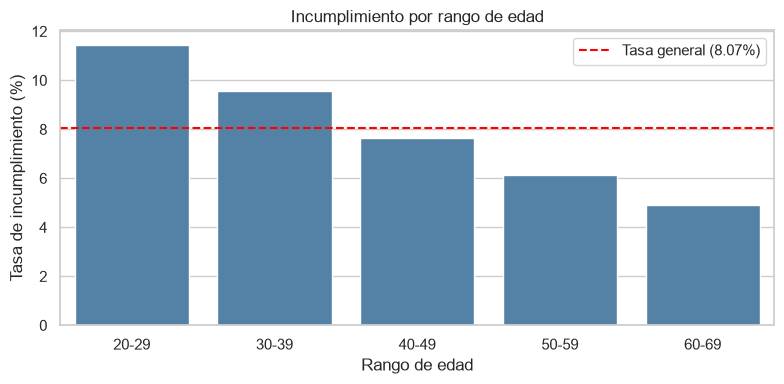

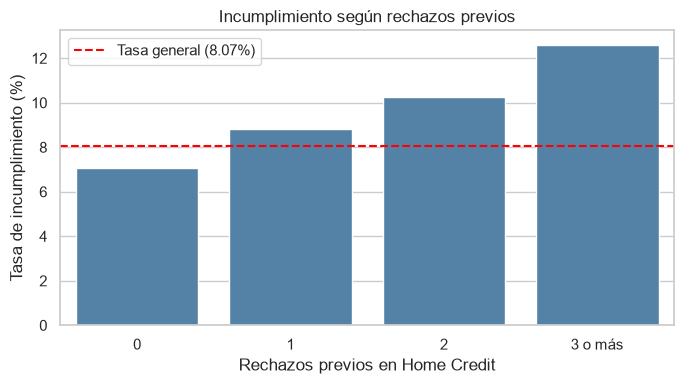

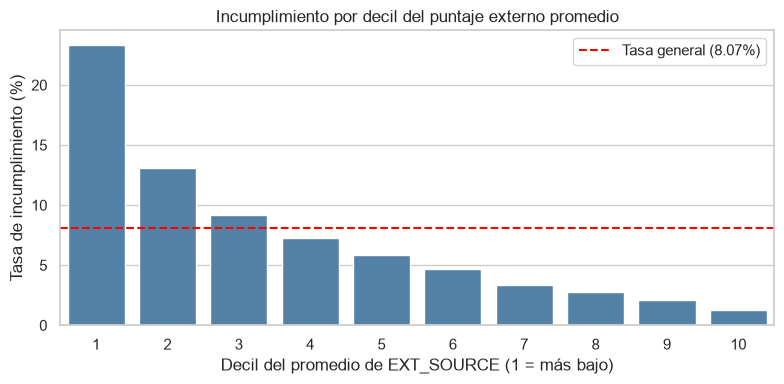

In [20]:
df = df.copy()

# 1) Incumplimiento por rango de edad
t_edad = tasa_por_grupo(df, "RANGO_EDAD").sort_values("RANGO_EDAD")
plt.figure(figsize=(8, 4))
sns.barplot(data=t_edad, x="RANGO_EDAD", y="tasa", color="steelblue")
plt.axhline(8.07, color="red", linestyle="--", label="Tasa general (8.07%)")
plt.xlabel("Rango de edad")
plt.ylabel("Tasa de incumplimiento (%)")
plt.title("Incumplimiento por rango de edad")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig("../imagenes/incumplimiento_por_edad.png", dpi=150)
plt.show()

# 2) Incumplimiento por rechazos previos (solo clientes con historial previo)
prev = df[df["PREV_SIN_HISTORIAL"] == 0].copy()
etiquetas = {0: "0", 1: "1", 2: "2", 3: "3 o más"}
prev["RECHAZOS"] = prev["PREV_NUM_RECHAZADAS"].clip(upper=3).astype(int).map(etiquetas)
t_rech = prev.groupby("RECHAZOS")["TARGET"].mean().mul(100).reindex(["0", "1", "2", "3 o más"])
plt.figure(figsize=(7, 4))
sns.barplot(x=t_rech.index, y=t_rech.values, color="steelblue")
plt.axhline(8.07, color="red", linestyle="--", label="Tasa general (8.07%)")
plt.xlabel("Rechazos previos en Home Credit")
plt.ylabel("Tasa de incumplimiento (%)")
plt.title("Incumplimiento según rechazos previos")
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig("../imagenes/rechazos_previos.png", dpi=150)
plt.show()

# 3) Incumplimiento por decil del promedio de EXT_SOURCE
cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
c = df.loc[df[cols].notna().all(axis=1), cols + ["TARGET"]].copy()
c["EXT_PROMEDIO"] = c[cols].mean(axis=1)
dec = pd.qcut(c["EXT_PROMEDIO"], 10, labels=False) + 1
t_ext = c.groupby(dec)["TARGET"].mean().mul(100)
plt.figure(figsize=(8, 4))
sns.barplot(x=t_ext.index, y=t_ext.values, color="steelblue")
plt.axhline(8.07, color="red", linestyle="--", label="Tasa general (8.07%)")
plt.xlabel("Decil del promedio de EXT_SOURCE (1 = más bajo)")
plt.ylabel("Tasa de incumplimiento (%)")
plt.title("Incumplimiento por decil del puntaje externo promedio")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig("../imagenes/ext_promedio_deciles.png", dpi=150)
plt.show()